# Line Integral of a Vector Field (Work along a Path)

This Colab notebook computes a line integral $ \int_C \mathbf{F}\cdot d\mathbf{r} $ for a **non-circular** 2D vector field over an **open** path.

**What you get:**
- A generic function to compute the line integral numerically (trapezoidal rule).
- A default example with a non-circular field and a sinusoidal open path.
- A plot (quiver + path), saved at 300 dpi.
- Easy cells to customize the field and the path.


In [7]:
# Imports (no seaborn; plain matplotlib)
import numpy as np
import matplotlib.pyplot as plt
from typing import Callable, Tuple

# ----------------------------- Utilities -----------------------------
def line_integral(F_fun: Callable[[np.ndarray, np.ndarray], Tuple[np.ndarray, np.ndarray]],
                  r_fun: Callable[[np.ndarray], Tuple[np.ndarray, np.ndarray]],
                  dr_fun: Callable[[np.ndarray], Tuple[np.ndarray, np.ndarray]],
                  t0: float,
                  t1: float,
                  n: int = 4000) -> Tuple[float, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Numerically compute ∫ F(r(t)) · r'(t) dt using the trapezoidal rule.
    Returns (value, t, x, y, Fx, Fy).
    """
    t = np.linspace(t0, t1, n + 1)
    x, y = r_fun(t)
    dxt, dyt = dr_fun(t)
    Fx, Fy = F_fun(x, y)
    integrand = Fx * dxt + Fy * dyt
    val = np.trapezoid(integrand, t)
    return val, t, x, y, Fx, Fy

def plot_field_and_path(F_fun, xlim=(-0.2, 1.2), ylim=(-1.0, 1.0), path_xy=None, dpi=300, fname=None):
    """Quiver plot of the vector field and optional path overlay."""
    grid_n = 21
    xs = np.linspace(xlim[0], xlim[1], grid_n)
    ys = np.linspace(ylim[0], ylim[1], grid_n)
    X, Y = np.meshgrid(xs, ys)
    FX, FY = F_fun(X, Y)
    plt.figure()
    plt.quiver(X, Y, FX, FY)
    if path_xy is not None:
        x, y = path_xy
        plt.plot(x, y, linewidth=2.5)
        plt.scatter([x[0]], [y[0]], s=50)
        plt.scatter([x[-1]], [y[-1]], s=50)
    plt.axis("equal")
    plt.title("Vector field and path")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.tight_layout()
    if fname:
        plt.savefig(fname, dpi=dpi)
    plt.show()


## Default example (non-circular field, open path)
- Field: $\mathbf{F}(x,y) = (x^2 + y, \; x - y^2)$
- Path: $\mathbf{r}(t) = (t,\; 0.5\sin(2\pi t))$, $t\in[0,1]$

Numerical line integral (work) over open path = 0.333333


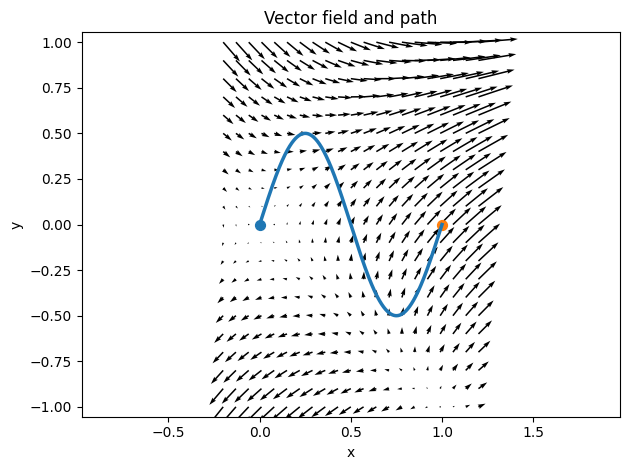

Figure saved to: vector_field_open_path.png


In [8]:
# ---- Define field and path ----
def F(x: np.ndarray, y: np.ndarray):
    Fx = x**2 + y
    Fy = x - y**2
    return Fx, Fy

def r(t: np.ndarray):
    x = t
    y = 0.5 * np.sin(2.0 * np.pi * t)
    return x, y

def dr_dt(t: np.ndarray):
    dx = np.ones_like(t)
    dy = 0.5 * 2.0 * np.pi * np.cos(2.0 * np.pi * t)
    return dx, dy

# ---- Compute integral ----
val_num, t, x, y, Fx, Fy = line_integral(F, r, dr_dt, 0.0, 1.0, n=4000)
print(f"Numerical line integral (work) over open path = {val_num:.6f}")

# ---- Plot and save ----
fig_path = "vector_field_open_path.png"
plot_field_and_path(F, xlim=(-0.2, 1.2), ylim=(-1.0, 1.0), path_xy=(x, y), dpi=300, fname=fig_path)
print(f"Figure saved to: {fig_path}")


## Customize your own field and path
Edit the functions below to try any 2D field and any open (or closed) path. Keep the signatures the same.

Custom field/path: work = 0.962500


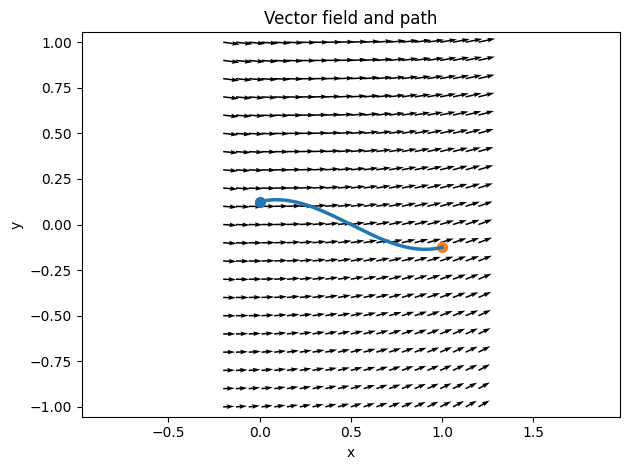

Saved: custom_field_path.png


In [9]:
# Example template to customize:
def F_custom(x: np.ndarray, y: np.ndarray):
    # Example: shear-like field
    Fx = 1.0 + 0.2 * y
    Fy = 0.3 * x - 0.1 * y
    return Fx, Fy

def r_custom(t: np.ndarray):
    # Example: cubic arc from (0,0) to (1,0)
    x = t
    y = (t - 0.5)**3 - 0.5*(t - 0.5)
    return x, y

def dr_dt_custom(t: np.ndarray):
    dx = np.ones_like(t)
    dy = 3*(t - 0.5)**2 - 0.5
    return dx, dy

# Run with the custom definitions
val_custom, tt, xc, yc, FXc, FYc = line_integral(F_custom, r_custom, dr_dt_custom, 0.0, 1.0, n=4000)
print(f"Custom field/path: work = {val_custom:.6f}")
plot_field_and_path(F_custom, xlim=(-0.2, 1.2), ylim=(-1.0, 1.0), path_xy=(xc, yc), dpi=300, fname="custom_field_path.png")
print("Saved: custom_field_path.png")
